<a href="https://colab.research.google.com/github/luca-fce/siniestros-futbol-caba/blob/main/notebook/3_2_cruce_partidos_siniestros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cruce partidos × siniestros viales (CABA, 2021–2025)

**Pregunta:** ¿Se registra un aumento significativo de siniestros viales en la Ciudad de Buenos Aires durante las 12 horas posteriores a la derrota de los equipos más populares de fútbol?

**Idea del método.** En la Ciudad hay muchos más siniestros a las 18 h que a las 4 h, y los sábados no se parecen a los martes. Por eso no alcanza con contar siniestros después de cada partido: hay que compararlos contra **lo que se esperaría a esa misma hora, ese mismo día de la semana y ese mismo año, cuando no hubo partido**. Para cada partido calculamos:

- **Observado:** siniestros en las 12 h posteriores al final del partido.
- **Esperado:** promedio de siniestros en ventanas de 12 h que arrancan a la misma hora, el mismo día de la semana y el mismo año, **sin ningún partido cerca** (ventanas de control).
- **Ratio = observado / esperado.** Un ratio de 1,10 significa 10 % más siniestros de lo normal.

Después comparamos el ratio de las **derrotas** contra el de **victorias y empates**, y testeamos si la diferencia es estadísticamente significativa.

> *Uso de IA:* este notebook fue armado con asistencia de Claude (Anthropic). Prompt utilizado: «Armá el cruce entre los partidos de River, Boca y la Selección y los siniestros viales de CABA 2021–2025, comparando las 12 h posteriores a cada derrota contra un control de misma hora, día de la semana y año, con test estadístico y tres gráficos». El grupo revisó el código, los resultados y redactó/validó las interpretaciones.

## 1. Librerías y carga de datos

Todo se lee directo desde el repositorio del grupo, así el notebook corre en Colab sin subir archivos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
import os

REPO = 'https://raw.githubusercontent.com/luca-fce/siniestros-futbol-caba/main/'
SEL_CSV = REPO + 'datos/partidos_seleccion_2021_2025.csv'
os.makedirs('figuras', exist_ok=True)

# Estilo de gráficos
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 10})
COLOR = {'Derrota': '#eb6834', 'Empate': '#2a78d6', 'Victoria': '#1baf7a', 'Esperado': '#8a8984'}
ORDEN = ['Derrota', 'Empate', 'Victoria']

hechos = pd.read_csv(REPO + 'datos/hechos_limpio_2021_2025.csv', parse_dates=['fecha_siniestro', 'fecha_hora'])
print('Siniestros 2021-2025:', len(hechos), '| con hora:', hechos['fecha_hora'].notna().sum())

Siniestros 2021-2025: 49602 | con hora: 49525


## 2. Partidos de River y Boca

Unimos los diez CSV anuales (FBref). Tres decisiones importantes:

1. **Hora argentina.** FBref muestra la hora local del estadio. Cuando el partido se jugó en otro huso horario, agrega la hora argentina entre paréntesis (ej. `19:30 (21:30)` en Ecuador). Usamos siempre la hora argentina.
2. **Penales.** FBref marca como empate (`D`) un partido definido por penales. Para el hincha, quedar eliminado por penales es una **derrota**, así que lo reclasificamos usando la columna `Notes`.
3. **Hora de finalización.** Inicio + 1 h 55 min (90' + entretiempo + adicionado). Si hubo alargue se suman 30 min y, si hubo penales, 15 min más.

In [2]:
archivos = {'Boca Juniors': 'Boca%20Juniors/boca_{}.csv', 'River Plate': 'River%20Plate/river_{}.csv'}
lista = []
for equipo, patron in archivos.items():
    for anio in range(2021, 2026):
        df = pd.read_csv(REPO + 'datos/Temporadas%20River%20-%20Boca/' + patron.format(anio))
        df['equipo'] = equipo
        lista.append(df)
clubes = pd.concat(lista, ignore_index=True)

# 1. Hora argentina: si hay paréntesis, esa es la hora argentina
clubes['hora_arg'] = clubes['Time'].str.extract(r'\((\d{2}:\d{2})\)')[0].fillna(clubes['Time'].str[:5])

# 2. Resultado final (penales incluidos)
notas = clubes['Notes'].fillna('')
penales = notas.str.contains('penalty shoot-out')
gano_penales = [eq in n and f'{eq} won a penalty' in n for eq, n in zip(clubes['equipo'], notas)]
clubes['resultado'] = clubes['Result'].map({'W': 'Victoria', 'D': 'Empate', 'L': 'Derrota'})
clubes.loc[penales & pd.Series(gano_penales), 'resultado'] = 'Victoria'
clubes.loc[penales & ~pd.Series(gano_penales), 'resultado'] = 'Derrota'

# 3. Inicio y fin del partido
clubes['inicio'] = pd.to_datetime(clubes['Date'] + ' ' + clubes['hora_arg'])
alargue = notas.str.contains('extra time', case=False)
clubes['fin'] = (clubes['inicio'] + pd.Timedelta(minutes=115)
                 + pd.to_timedelta(np.where(alargue, 30, 0), unit='min')
                 + pd.to_timedelta(np.where(penales, 15, 0), unit='min'))

clubes = clubes.rename(columns={'Comp': 'competencia', 'Venue': 'condicion', 'Opponent': 'rival',
                                'GF': 'goles_a_favor', 'GA': 'goles_en_contra'})
clubes['rival'] = clubes['rival'].str.replace(r'^[a-z]{2} ', '', regex=True)  # saca el código de país
clubes['superclasico'] = clubes['rival'].isin(['River Plate', 'Boca Juniors'])
cols = ['equipo', 'inicio', 'fin', 'competencia', 'condicion', 'rival', 'goles_a_favor', 'goles_en_contra', 'resultado', 'superclasico']
clubes = clubes[cols]
print('Partidos por penales reclasificados:', penales.sum())
clubes.groupby('equipo')['resultado'].value_counts().unstack()

Partidos por penales reclasificados: 17


resultado,Derrota,Empate,Victoria
equipo,,,
Boca Juniors,65,64,120
River Plate,57,65,130


## 3. Partidos de la Selección Argentina

Se leen de `datos/partidos_seleccion_2021_2025.csv`, generado en `3_1_seleccion.ipynb`, que ya trae la hora de inicio en hora argentina (fuente: Wikipedia), el resultado final con penales incluidos y si hubo alargue o penales. Se aplican las mismas reglas de finalización que a los clubes.

In [3]:
try:
    sel = pd.read_csv(SEL_CSV)
    sel['equipo'] = 'Selección Argentina'
    sel['inicio'] = pd.to_datetime(sel['fecha'] + ' ' + sel['hora_arg'])
    extra = (sel.get('alargue', False).astype(bool) * 30 + sel.get('penales', False).astype(bool) * 15)
    sel['fin'] = sel['inicio'] + pd.Timedelta(minutes=115) + pd.to_timedelta(extra, unit='min')
    sel['superclasico'] = False
    partidos = pd.concat([clubes, sel[cols]], ignore_index=True)
    print('Selección incluida:', len(sel), 'partidos')
except Exception as e:
    partidos = clubes.copy()
    print('Todavía no está el archivo de la Selección -> se analiza solo River y Boca.')

partidos = partidos.sort_values('inicio').reset_index(drop=True)
print('Partidos totales:', len(partidos))
partidos.head()

Selección incluida: 67 partidos
Partidos totales: 568


,equipo,inicio,fin,competencia,condicion,rival,goles_a_favor,goles_en_contra,resultado,superclasico
0,Boca Juniors,2021-02-14 19:20:00,2021-02-14 21:15:00,Copa de la Liga Profesional,Home,Gimnasia–LP,2,2,Empate,False
1,River Plate,2021-02-14 21:30:00,2021-02-14 23:25:00,Copa de la Liga Profesional,Away,Estudiantes–LP,1,2,Derrota,False
2,River Plate,2021-02-20 21:30:00,2021-02-20 23:25:00,Copa de la Liga Profesional,Home,Rosario Central,3,0,Victoria,False
3,Boca Juniors,2021-02-21 21:30:00,2021-02-21 23:25:00,Copa de la Liga Profesional,Away,Newell's,1,0,Victoria,False
4,River Plate,2021-02-28 17:10:00,2021-02-28 19:05:00,Copa de la Liga Profesional,Away,Platense,1,0,Victoria,False


## 4. Serie horaria de siniestros y ventanas de 12 h

Transformación clave: pasamos los siniestros a una **serie por hora** (incluyendo las horas con cero) y calculamos, para cada hora `t`, la suma de siniestros de las 12 h siguientes. Así, el valor de un partido es simplemente esa suma en la hora en que terminó.

Los 77 siniestros sin hora registrada (0,16 %) no se pueden ubicar en una ventana y se excluyen.

In [4]:
horas = pd.date_range('2021-01-01 00:00', '2025-12-31 23:00', freq='h')
serie = (hechos.dropna(subset=['fecha_hora'])
         .set_index('fecha_hora').resample('h').size()
         .reindex(horas, fill_value=0))
# suma de las 12 horas siguientes (t, t+1, ..., t+11)
ventana12 = serie.rolling(12).sum().shift(-11)

base = pd.DataFrame({'siniestros_12h': ventana12})
base['anio'] = base.index.year
base['dia_semana'] = base.index.dayofweek
base['hora'] = base.index.hour
print('Promedio de siniestros en 12 h:', round(ventana12.mean(), 2))

Promedio de siniestros en 12 h: 13.56


### Ventanas de control

Una hora es **control** si su ventana de 12 h no se superpone con la ventana de ningún partido (de ningún equipo). El valor **esperado** de un partido es el promedio de las ventanas de control con el mismo año, día de la semana y hora de inicio. Así el control descuenta el horario, el día y la tendencia de cada año.

In [5]:
partidos['inicio_ventana'] = partidos['fin'].dt.floor('h')
inicios = partidos['inicio_ventana'].values

# marcar horas a menos de 12 h de cualquier inicio de ventana de partido
contaminada = pd.Series(False, index=horas)
for w in partidos['inicio_ventana']:
    contaminada[(horas > w - pd.Timedelta(hours=12)) & (horas < w + pd.Timedelta(hours=12))] = True
base['control'] = ~contaminada & base['siniestros_12h'].notna()
print(f"Horas de control: {base['control'].sum():,} de {len(base):,} ({base['control'].mean():.0%})")

esperado = (base[base['control']]
            .groupby(['anio', 'dia_semana', 'hora'])['siniestros_12h'].mean()
            .rename('esperado'))

partidos['anio'] = partidos['inicio_ventana'].dt.year
partidos['dia_semana'] = partidos['inicio_ventana'].dt.dayofweek
partidos['hora'] = partidos['inicio_ventana'].dt.hour
partidos['observado'] = ventana12.reindex(partidos['inicio_ventana']).values
partidos = partidos.join(esperado, on=['anio', 'dia_semana', 'hora'])
partidos['exceso'] = partidos['observado'] - partidos['esperado']
partidos['ratio'] = partidos['observado'] / partidos['esperado']
partidos = partidos.dropna(subset=['observado', 'esperado'])
partidos[['equipo', 'inicio', 'rival', 'resultado', 'observado', 'esperado', 'ratio']].head(10)

Horas de control: 32,491 de 43,824 (74%)


,equipo,inicio,rival,resultado,observado,esperado,ratio
0,Boca Juniors,2021-02-14 19:20:00,Gimnasia–LP,Empate,2.0,6.047619,0.330709
1,River Plate,2021-02-14 21:30:00,Estudiantes–LP,Derrota,1.0,6.857143,0.145833
2,River Plate,2021-02-20 21:30:00,Rosario Central,Victoria,6.0,5.064516,1.184713
3,Boca Juniors,2021-02-21 21:30:00,Newell's,Victoria,4.0,6.857143,0.583333
4,River Plate,2021-02-28 17:10:00,Platense,Victoria,10.0,5.666667,1.764706
5,Boca Juniors,2021-02-28 21:30:00,Sarmiento–J,Empate,5.0,6.857143,0.729167
6,Boca Juniors,2021-03-07 21:30:00,Vélez Sarsfield,Victoria,6.0,6.857143,0.875000
7,River Plate,2021-03-08 21:30:00,Arg Juniors,Derrota,4.0,6.363636,0.628571
8,River Plate,2021-03-14 18:00:00,Boca Juniors,Empate,7.0,5.666667,1.235294
9,Boca Juniors,2021-03-14 18:00:00,River Plate,Empate,7.0,5.666667,1.235294


## 5. Resumen estadístico agrupado

In [6]:
resumen = (partidos.groupby('resultado')
           .agg(partidos=('ratio', 'size'),
                observado_medio=('observado', 'mean'),
                esperado_medio=('esperado', 'mean'),
                ratio_medio=('ratio', 'mean'),
                exceso_medio=('exceso', 'mean'))
           .reindex(ORDEN).round(2))
resumen

,partidos,observado_medio,esperado_medio,ratio_medio,exceso_medio
resultado,,,,,
Derrota,127,8.07,8.12,0.99,-0.05
Empate,137,7.79,7.84,1.01,-0.06
Victoria,304,8.53,8.18,1.04,0.35


In [7]:
por_equipo = (partidos.groupby(['equipo', 'resultado'])
              .agg(partidos=('ratio', 'size'), ratio_medio=('ratio', 'mean'), exceso_medio=('exceso', 'mean'))
              .round(2))
por_equipo

partidos  ratio_medio  exceso_medio
equipo              resultado                                     
Boca Juniors        Derrota          65         0.99         -0.11
                    Empate           64         1.04          0.08
                    Victoria        120         1.07          0.48
River Plate         Derrota          57         0.98         -0.13
                    Empate           65         0.99         -0.17
                    Victoria        130         1.00          0.03
Selección Argentina Derrota           5         1.19          1.63
                    Empate            8         0.93         -0.22
                    Victoria         54         1.08          0.81

**Interpretación.** En las 12 h posteriores a una derrota se registraron en promedio **8,07 siniestros**, contra **8,12 esperados** para ese horario, día y año: un ratio de **0,99**, es decir, exactamente lo normal. Tras empates el ratio es 1,01 y tras victorias 1,04. Por equipo, las derrotas de Boca (0,99) y de River (0,98) tampoco muestran aumento. La Selección tiene un ratio alto en derrotas (1,19), pero con **solo 5 partidos**, un número demasiado chico para sacar conclusiones; lo analizamos caso por caso más abajo. Llama la atención que el valor más alto entre los grupos grandes sea el de las **victorias** de la Selección (1,08) y de Boca (1,07), no el de las derrotas.

## 6. ¿La diferencia es significativa?

Usamos tres pruebas complementarias:

1. **¿Las derrotas tienen más siniestros de lo esperado?** Test de Wilcoxon (una muestra) sobre el exceso de las derrotas, contra 0.
2. **¿Las derrotas tienen más exceso que victorias y empates?** Test de Mann-Whitney (no asume normalidad).
3. **Regresión de Poisson** (modelo estándar para conteos): `observado ~ derrota + empate + equipo`, usando el esperado como *offset*. El coeficiente de derrota, exponenciado, es el **cambio porcentual** de siniestros tras una derrota respecto de una victoria, ya controlado por hora, día y año. Se usa la versión *quasi-Poisson* para corregir la sobredispersión.

Nivel de significación: 5 %.

In [8]:
derrotas = partidos.loc[partidos['resultado'] == 'Derrota', 'exceso']
no_derrotas = partidos.loc[partidos['resultado'] != 'Derrota', 'exceso']

w = stats.wilcoxon(derrotas, alternative='greater')
mw = stats.mannwhitneyu(derrotas, no_derrotas, alternative='greater')
print(f'1) Wilcoxon exceso derrotas > 0:        p = {w.pvalue:.3f}  (exceso medio {derrotas.mean():+.2f} siniestros)')
print(f'2) Mann-Whitney derrotas > no derrotas:  p = {mw.pvalue:.3f}')

partidos['derrota'] = (partidos['resultado'] == 'Derrota').astype(int)
partidos['empate'] = (partidos['resultado'] == 'Empate').astype(int)
modelo = smf.glm('observado ~ derrota + empate + C(equipo)', data=partidos,
                 family=sm.families.Poisson(), offset=np.log(partidos['esperado'])).fit(scale='X2')
coef = modelo.params['derrota']; ic = modelo.conf_int().loc['derrota']
print(f'3) Poisson: derrota vs victoria = {np.exp(coef)-1:+.1%} siniestros '
      f'(IC 95%: {np.exp(ic[0])-1:+.1%} a {np.exp(ic[1])-1:+.1%}), p = {modelo.pvalues["derrota"]:.3f}')

1) Wilcoxon exceso derrotas > 0:        p = 0.721  (exceso medio -0.05 siniestros)
2) Mann-Whitney derrotas > no derrotas:  p = 0.786
3) Poisson: derrota vs victoria = -4.1% siniestros (IC 95%: -11.8% a +4.4%), p = 0.335


In [9]:
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              observado   No. Observations:                  568
Model:                            GLM   Df Residuals:                      563
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.3082
Method:                          IRLS   Log-Likelihood:                -1123.4
Date:                Wed, 04 Nov 2026   Deviance:                       747.51
Time:                        03:41:10   Pearson chi2:                     737.
No. Iterations:                     6   Pseudo R-squ. (CS):           0.007666
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                            0.0490      0.031      1.593      0.111      -0.011       0.109
C(equipo)[T.River Plate]            -0.0364      0.036     -1.008      0.313      -0.107       0.034
C(equipo)[T.Selección Argentina]     0.0373      0.052      0.710      0.478      -0.066       0.140
derrota                             -0.0414      0.043     -0.965      0.335      -0.126       0.043
empate                              -0.0406      0.042     -0.960      0.337      -0.124       0.042
====================================================================================================
"""

**Interpretación.** Ninguna de las tres pruebas encuentra un aumento significativo:

- El exceso de siniestros tras las derrotas no es mayor que cero (Wilcoxon, p = 0,72).
- Las derrotas no tienen más exceso que victorias y empates (Mann-Whitney, p = 0,79).
- En la regresión de Poisson, una derrota se asocia con un **4,1 % menos** de siniestros que una victoria, pero el intervalo de confianza (−11,8 % a +4,4 %) incluye el cero (p = 0,34).

Con un nivel de significación del 5 %, **no se rechaza la hipótesis nula**: con estos datos no hay evidencia de que las derrotas aumenten los siniestros viales en las 12 h siguientes. El intervalo de confianza permite además descartar efectos grandes: un aumento mayor al ~4 % tras una derrota es poco compatible con los datos. El leve exceso tras las victorias tampoco es significativo (Wilcoxon bilateral, p = 0,28).

### Las 5 derrotas de la Selección, caso por caso

Con solo 5 derrotas no tiene sentido un test estadístico para la Selección sola, así que las describimos una por una.

In [10]:
(partidos[(partidos['equipo'] == 'Selección Argentina') & (partidos['resultado'] == 'Derrota')]
 [['inicio', 'rival', 'competencia', 'observado', 'esperado', 'ratio']].round({'esperado': 2, 'ratio': 2}))

,inicio,rival,competencia,observado,esperado,ratio
224,2022-11-22 07:00:00,Saudi Arabia,FIFA World Cup,22.0,22.22,0.99
340,2023-11-16 21:00:00,Uruguay,FIFA World Cup qualification,9.0,7.78,1.16
432,2024-09-10 19:30:00,Colombia,FIFA World Cup qualification,5.0,7.08,0.71
457,2024-11-14 20:30:00,Paraguay,FIFA World Cup qualification,11.0,8.67,1.27
540,2025-09-09 20:00:00,Ecuador,FIFA World Cup qualification,15.0,8.10,1.85


**Interpretación.** Las 5 derrotas de la Selección muestran resultados muy dispares: tras Ecuador (2025) hubo un 85 % más de siniestros de lo esperado y tras Paraguay (2024) un 27 % más, pero tras Colombia (2024) un 29 % menos, y tras la derrota con Arabia Saudita en el Mundial, jugada un martes a las 7 de la mañana, los siniestros fueron exactamente los normales (22 contra 22,2). Con tan pocos casos y tanta dispersión no se puede afirmar que haya un efecto.

Como dato llamativo, el mayor exceso de todo el período se dio tras una **victoria**: la **final del Mundial 2022** contra Francia, con 19 siniestros contra 9,7 esperados (casi el doble), en un día en que millones de personas salieron a festejar a la calle. Esto sugiere que, si el fútbol influye en los siniestros, lo haría más por la **movilización masiva** que por la frustración de perder.

## 7. Gráficos

### 7.a Evolución temporal de los siniestros

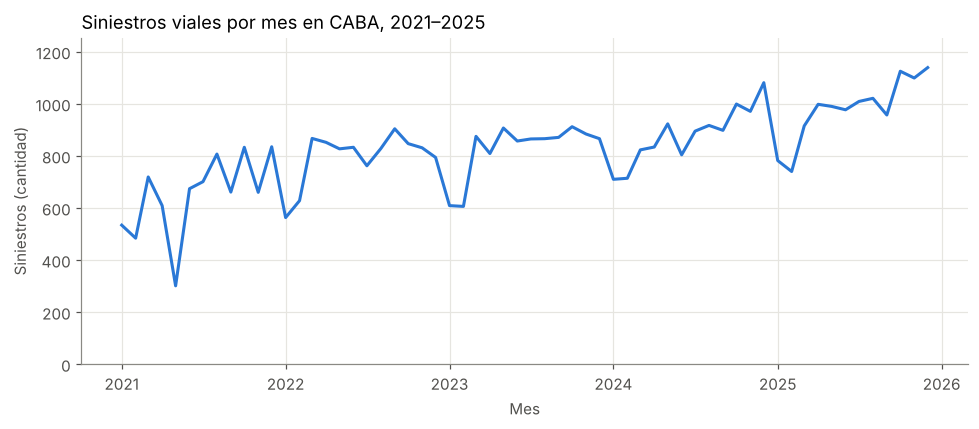

In [11]:
mensual = hechos.set_index('fecha_siniestro').resample('MS').size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mensual.index, mensual.values, color='#2a78d6', linewidth=2)
ax.set_title('Siniestros viales por mes en CABA, 2021–2025', loc='left', fontsize=12)
ax.set_xlabel('Mes'); ax.set_ylabel('Siniestros (cantidad)')
ax.set_ylim(0, mensual.max() * 1.1)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout(); plt.savefig('figuras/01_siniestros_mensuales.png', dpi=200); plt.show()

**Interpretación.** Los siniestros crecen de forma sostenida entre 2021 y 2025 (de unos 600–800 por mes a más de 1.000). La caída de 2021 refleja las restricciones de circulación por la pandemia, y los pozos de cada enero muestran el efecto de las vacaciones de verano, cuando baja la circulación en la Ciudad. Esta tendencia es la razón por la que el valor esperado se calcula **por año**: si no, los partidos de 2025 parecerían "con más siniestros" solo porque 2025 tuvo más siniestros en general.

### 7.b Comparación por resultado

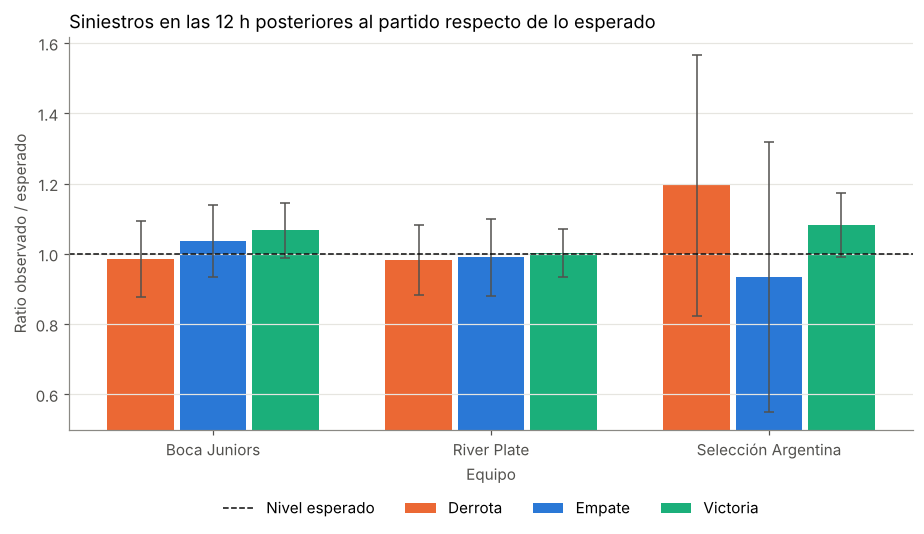

In [12]:
g = partidos.groupby(['equipo', 'resultado'])['ratio']
media = g.mean().unstack()[ORDEN]
error = (g.std() / np.sqrt(g.size()) * 1.96).unstack()[ORDEN]

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(media.index)); ancho = 0.26
for i, res in enumerate(ORDEN):
    ax.bar(x + (i - 1) * ancho, media[res], width=ancho - 0.02, color=COLOR[res], label=res,
           yerr=error[res], capsize=3, error_kw={'ecolor': '#52514e', 'linewidth': 1})
ax.axhline(1, color='#0b0b0b', linewidth=1, linestyle='--', label='Nivel esperado')
ax.grid(axis='x', visible=False)
ax.set_xticks(x); ax.set_xticklabels(media.index)
ax.set_ylim(min(0.8, (media - error).min().min() - 0.05), (media + error).max().max() + 0.05)
ax.set_title('Siniestros en las 12 h posteriores al partido respecto de lo esperado', loc='left', fontsize=12)
ax.set_ylabel('Ratio observado / esperado'); ax.set_xlabel('Equipo')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.savefig('figuras/02_ratio_por_resultado.png', dpi=200); plt.show()

**Interpretación.** En Boca y River, las barras de derrota (naranja) quedan apenas por debajo del nivel esperado y sus intervalos de confianza (líneas negras) cruzan ampliamente el 1: no hay ningún salto después de perder. En la Selección la barra de derrota es la más alta, pero su intervalo es enorme (va de 0,8 a 1,6) porque se apoya en solo 5 partidos. Gráficamente se ve por qué el resultado de la Selección sola no es concluyente.

### 7.c Relación entre esperado y observado

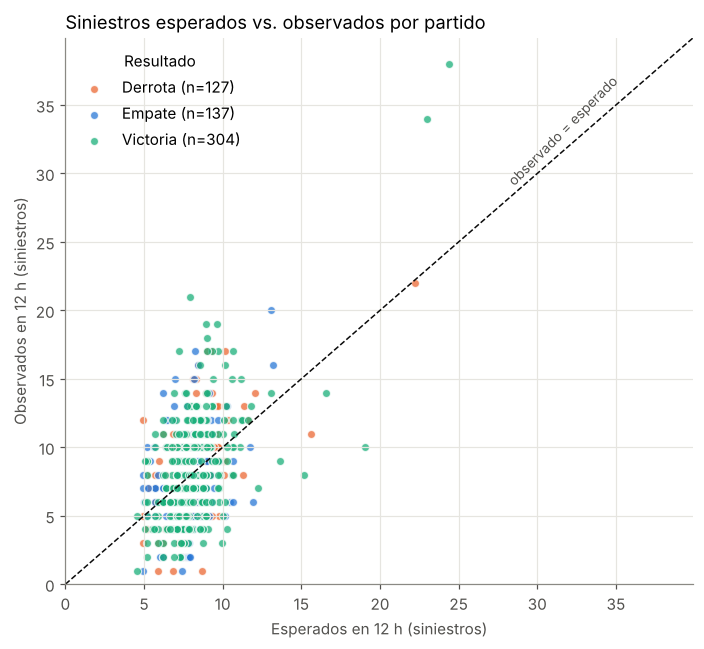

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for res in ORDEN:
    d = partidos[partidos['resultado'] == res]
    ax.scatter(d['esperado'], d['observado'], s=28, color=COLOR[res], alpha=0.75,
               edgecolor='white', linewidth=0.8, label=f'{res} (n={len(d)})')
lim = [0, partidos[['esperado', 'observado']].max().max() * 1.05]
ax.plot(lim, lim, color='#0b0b0b', linewidth=1, linestyle='--')
ax.text(lim[1] * 0.70, lim[1] * 0.73, 'observado = esperado', ha='left', fontsize=9, color='#52514e', rotation=45)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title('Siniestros esperados vs. observados por partido', loc='left', fontsize=12)
ax.set_xlabel('Esperados en 12 h (siniestros)'); ax.set_ylabel('Observados en 12 h (siniestros)')
ax.legend(title='Resultado', frameon=False)
plt.tight_layout(); plt.savefig('figuras/03_esperado_vs_observado.png', dpi=200); plt.show()

**Interpretación.** Cada punto es un partido (568 en total). Si las derrotas generaran más siniestros, los puntos naranjas deberían concentrarse por encima de la diagonal. En cambio, los tres colores se mezclan de forma pareja a ambos lados: lo que explica cuántos siniestros hay después de un partido es sobre todo **la hora y el día** en que termina (eje horizontal), no el resultado. Los pocos puntos con muchos siniestros esperados (a la derecha) corresponden a partidos que terminaron de día, como los del Mundial de Qatar.

### 7.d Hora por hora después del partido

Líneas superpuestas: siniestros promedio en cada una de las 12 horas posteriores al partido, para derrotas y victorias, comparados con el control.

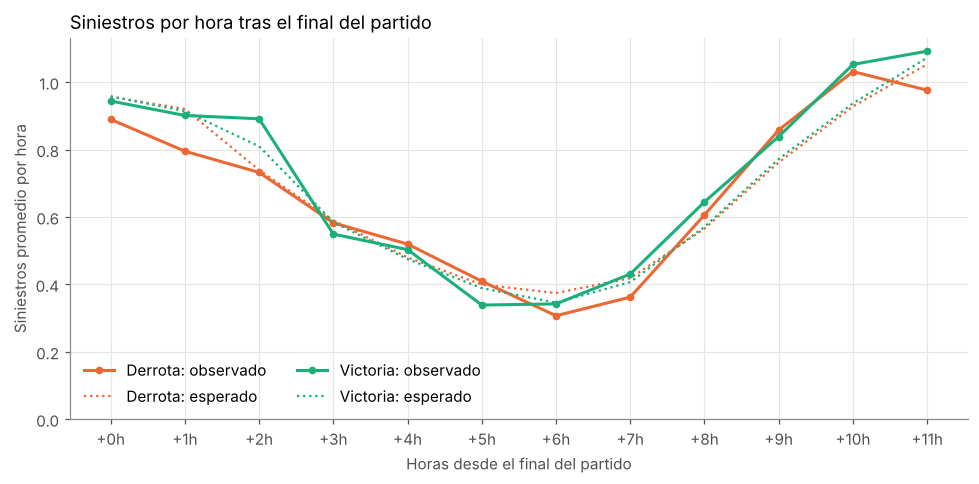

In [14]:
desfases = range(12)
esperado_h = base[base['control']].assign(s=serie).groupby(['anio', 'dia_semana', 'hora'])['s'].mean()
def perfil(df):
    obs, esp = [], []
    for k in desfases:
        t = df['inicio_ventana'] + pd.Timedelta(hours=k)
        obs.append(serie.reindex(t).mean())
        claves = list(zip(t.dt.year, t.dt.dayofweek, t.dt.hour))
        esp.append(esperado_h.reindex(claves).mean())
    return np.array(obs), np.array(esp)

fig, ax = plt.subplots(figsize=(9, 4.5))
for res in ['Derrota', 'Victoria']:
    obs, esp = perfil(partidos[partidos['resultado'] == res])
    ax.plot(desfases, obs, color=COLOR[res], linewidth=2, marker='o', markersize=4, label=f'{res}: observado')
    ax.plot(desfases, esp, color=COLOR[res], linewidth=1.5, linestyle=':', label=f'{res}: esperado')
ax.set_xticks(list(desfases)); ax.set_xticklabels([f'+{k}h' for k in desfases])
ax.set_title('Siniestros por hora tras el final del partido', loc='left', fontsize=12)
ax.set_xlabel('Horas desde el final del partido'); ax.set_ylabel('Siniestros promedio por hora')
ax.set_ylim(0, None)
ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.savefig('figuras/04_perfil_horario.png', dpi=200); plt.show()

**Interpretación.** La curva sigue el ritmo normal de la Ciudad: como la mayoría de los partidos termina de noche, los siniestros bajan durante la madrugada (+4 h a +7 h) y vuelven a subir con la actividad de la mañana siguiente. Tras las derrotas, la curva observada (línea llena) se pega a la esperada (punteada) en todas las horas, también en las primeras horas tras el partido, cuando uno esperaría el efecto más fuerte si existiera.

## 8. Exportación

In [15]:
partidos.drop(columns=['derrota', 'empate']).to_csv('partidos_con_siniestros_12h.csv', index=False)
print('Guardado partidos_con_siniestros_12h.csv y los gráficos en la carpeta figuras/')

Guardado partidos_con_siniestros_12h.csv y los gráficos en la carpeta figuras/


## 9. Conclusión

**¿Se registra un aumento significativo de siniestros viales en CABA durante las 12 horas posteriores a la derrota de los equipos más populares?** Con los **568 partidos** de River, Boca y la Selección entre 2021 y 2025 (127 derrotas), **no**. Tras una derrota los siniestros se mantienen en el nivel esperado para ese horario, día y año (ratio 0,99), y ninguna prueba estadística detecta diferencias significativas respecto de victorias o empates. El resultado se repite por separado en Boca y en River; la Selección tiene muy pocas derrotas (5) para evaluarla sola. El caso más llamativo del período es una victoria: la final del Mundial 2022, con casi el doble de siniestros de lo esperado.

**Limitaciones:**
- La base solo registra siniestros con víctimas (lesiones u homicidios culposos); los choques solo con daños materiales no aparecen.
- No sabemos si los involucrados vieron el partido ni de qué equipo son hinchas.
- La hora de fin del partido es aproximada (inicio + 1 h 55 min, más alargue y penales).
- Las ventanas de distintos equipos a veces se superponen (y en los superclásicos un equipo gana y el otro pierde).
- Faltan la Copa Argentina y las supercopas de River y Boca.
- Los partidos jugados fuera del país pueden afectar menos el tránsito porteño que los locales.

**Posibles extensiones:** separar partidos de local en CABA, mirar solo siniestros graves y mortales, analizar eliminaciones o finales por separado, y estudiar el efecto de los festejos masivos.